<a href="https://colab.research.google.com/github/oumaklaus/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/Sentiment_Reviews_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Data Loading

In [ ]:
import os
import urllib.request

base_url = "https://raw.githubusercontent.com/oumaklaus/Datheon_Machine_Learning_-_Data_Science_Internship/main/sentiment_reviews.csv"
csv_file = "sentiment_reviews.csv"

if not os.path.exists(csv_file):
    try:
        urllib.request.urlretrieve(base_url, csv_file)
    except Exception as exc:
        raise FileNotFoundError(
            "sentiment_reviews.csv not found - upload it next to this notebook "
            "(or add it to the GitHub repo)."
        ) from exc

In [ ]:
!ls

agents				   pytest.ini
California_Housing_Pipeline.ipynb  README.md
CHANGELOG.md			   README_ZH.md
claude				   requirements-dev.txt
codex				   requirements.txt
config.toml			   scan_top1000.txt
CONTRIBUTING.md			   scripts
GUIDE.md			   sentiment_reviews.csv
GUIDE_ZH.md			   Sentiment_Reviews_Pipeline.ipynb
housing.csv			   Telco_Churn_Pipeline.ipynb
images				   templates
instruction.ctf.md		   tests
LICENSE				   work_ctf_zc.c
ml-books			   work-linux


In [ ]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# NLTK resources (downloaded once per runtime)
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as exc:
        print(f"Could not download {pkg}: {exc}")

In [ ]:
df = pd.read_csv("sentiment_reviews.csv")

# 2. EDA

In [ ]:
df.shape

(10, 3)

In [ ]:
df.head()

,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [ ]:
df.tail()

,review_id,review_text,sentiment
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes


In [ ]:
df.describe()

,review_id
count,10.00000
mean,5.50000
std,3.02765
min,1.00000
25%,3.25000
50%,5.50000
75%,7.75000
max,10.00000


In [ ]:
df["sentiment"].value_counts()

sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

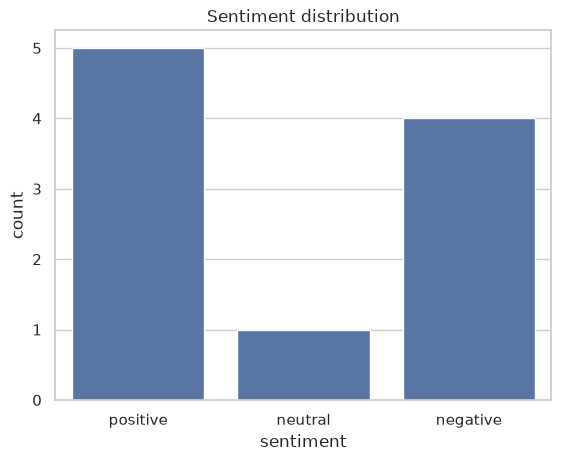

In [ ]:
sns.countplot(data=df, x="sentiment", order=["positive", "neutral", "negative"])
plt.title("Sentiment distribution")
plt.show()

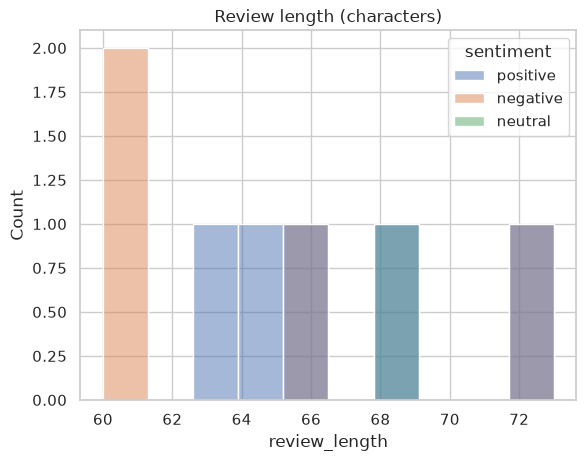

In [ ]:
df["review_length"] = df["review_text"].str.len()

sns.histplot(data=df, x="review_length", bins=10, hue="sentiment")
plt.title("Review length (characters)")
plt.show()

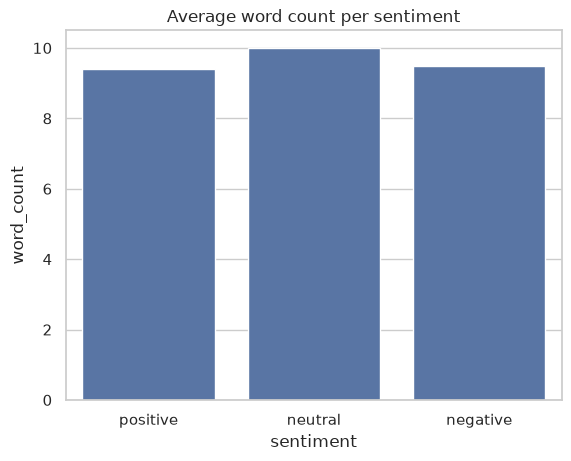

In [ ]:
df["word_count"] = df["review_text"].str.split().str.len()

sns.barplot(data=df, x="sentiment", y="word_count",
            order=["positive", "neutral", "negative"], errorbar=None)
plt.title("Average word count per sentiment")
plt.show()

## 3. Text Preprocessing

In [ ]:
# Keep negation words - removing "not"/"never" would flip the meaning of a review
NEGATIONS = {"not", "no", "nor", "never", "n't"}

try:
    STOPWORDS = set(stopwords.words("english")) - NEGATIONS
except LookupError:
    STOPWORDS = {
        "a", "an", "the", "and", "or", "but", "if", "of", "at", "by", "for",
        "with", "about", "as", "is", "are", "was", "were", "be", "been",
        "being", "to", "from", "in", "on", "that", "this", "these", "those",
        "it", "its", "i", "my", "we", "our", "you", "your", "he", "she",
        "they", "them", "his", "her", "their", "have", "has", "had", "do",
        "does", "did", "will", "would", "can", "could", "should", "than",
        "so", "too", "very", "just", "also",
    } - NEGATIONS

lemmatizer = WordNetLemmatizer()


def lemmatize(word):
    """Lemmatize with both noun and verb readings (fixes e.g. "dies" -> "dy")."""
    try:
        noun = lemmatizer.lemmatize(word, pos="n")
        verb = lemmatizer.lemmatize(word, pos="v")
    except LookupError:
        return word
    if verb != word and noun == word:
        return verb
    if noun != word and verb == word:
        return noun
    if noun != word and verb != word:
        return verb
    return noun


def clean_text(text):
    """Lowercase, strip HTML/URLs/punctuation/digits, remove stopwords, lemmatize."""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)              # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # URLs
    text = re.sub(r"[^a-z\s]", " ", text)             # punctuation & digits
    tokens = text.split()
    tokens = [t for t in tokens
              if (t not in STOPWORDS or t in NEGATIONS) and len(t) > 1]
    tokens = [lemmatize(t) for t in tokens]
    return " ".join(tokens)


print(clean_text("<b>Absolutely LOVE this!</b> Easy to setup... works flawlessly :) 10/10"))

absolutely love easy setup work flawlessly


In [ ]:
df["clean_text"] = df["review_text"].apply(clean_text)

df[["review_text", "clean_text", "sentiment"]]

,review_text,clean_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceed expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrive complete...,negative
2,"Average performance, decent for the price poin...",average performance decent price point nothing...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stop work two day extremely disappoint purchase,negative
5,Customer support helped resolve my setup quest...,customer support help resolve setup question w...,positive
6,Delivery was slow and package was missing one ...,delivery slow package miss one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


## 4. Dataset Splitting

In [ ]:
X = df["clean_text"]
y = df["sentiment"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

In [ ]:
print("X Train:", X_train.shape)
print("X Test: ", X_test.shape)
print()
print("Train labels:\n", y_train.value_counts().to_string())
print()
print("Test labels:\n", y_test.value_counts().to_string())

X Train: (7,)
X Test:  (3,)

Train labels:
 sentiment
positive    4
negative    2
neutral     1

Test labels:
 sentiment
negative    2
positive    1


## 5. TF-IDF Vectorization

In [ ]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=1)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
print("Train TF-IDF matrix:", X_train_tfidf.shape)
print("Test TF-IDF matrix: ", X_test_tfidf.shape)
print("Vocabulary size    :", len(vectorizer.vocabulary_))
print("Sample features    :", vectorizer.get_feature_names_out()[:15])

Train TF-IDF matrix: (7, 85)
Test TF-IDF matrix:  (3, 85)
Vocabulary size    : 85
Sample features    : ['absolutely' 'absolutely love' 'adapter' 'adapter cable' 'average'
 'average performance' 'build' 'build would' 'cable' 'clean'
 'clean interface' 'control' 'control highly' 'day' 'day extremely']


## 6. Model Training

In [ ]:
nb = MultinomialNB()
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)

nb.fit(X_train_tfidf, y_train)
log_reg.fit(X_train_tfidf, y_train)

pred_nb = nb.predict(X_test_tfidf)
pred_lr = log_reg.predict(X_test_tfidf)

## 7. Model Evaluation

In [ ]:
def report(name, y_true, y_pred):
    print(name)
    print(classification_report(y_true, y_pred, zero_division=0))
    print("-" * 60)


report("Multinomial Naive Bayes", y_test, pred_nb)
report("Logistic Regression", y_test, pred_lr)

Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

------------------------------------------------------------
Logistic Regression


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

------------------------------------------------------------


In [ ]:
benchmarks = pd.DataFrame([
    {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, pred, average="weighted", zero_division=0),
    }
    for name, pred in [("Multinomial Naive Bayes", pred_nb),
                       ("Logistic Regression", pred_lr)]
]).set_index("model").round(3)

benchmarks

,accuracy,macro_f1,weighted_f1
model,,,
Multinomial Naive Bayes,0.333,0.25,0.167
Logistic Regression,0.333,0.25,0.167


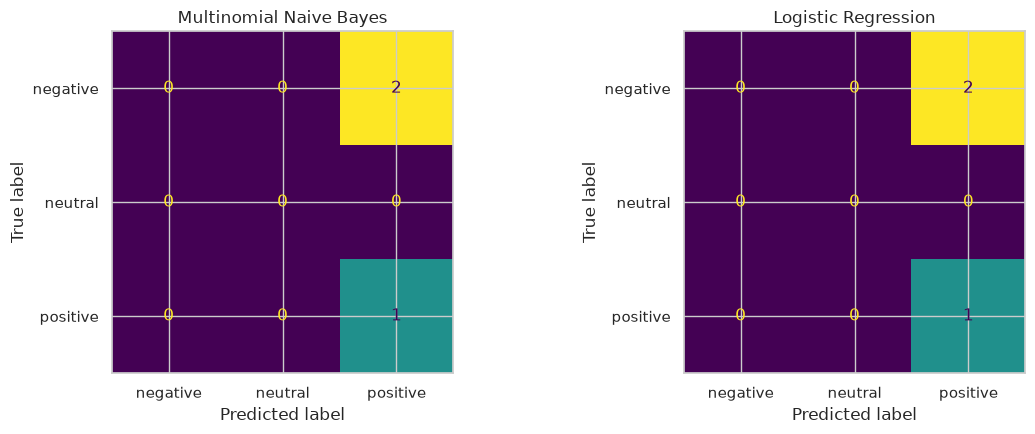

In [ ]:
labels = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, [("Multinomial Naive Bayes", pred_nb),
                                   ("Logistic Regression", pred_lr)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 8. Feature Importance (Top TF-IDF Tokens per Class)

In [ ]:
feature_names = np.array(vectorizer.get_feature_names_out())


def top_tokens_per_class(model, n=8):
    for i, label in enumerate(model.classes_):
        if hasattr(model, "feature_log_prob_"):
            # Naive Bayes: highest log-probability tokens for the class
            scores = model.feature_log_prob_[i]
        else:
            # Logistic Regression: largest positive coefficients for the class
            scores = model.coef_[i]
        top_idx = np.argsort(scores)[-n:][::-1]
        print(f"{label:>9}: {', '.join(feature_names[top_idx])}")


print("Naive Bayes")
top_tokens_per_class(nb)
print()
print("Logistic Regression")
top_tokens_per_class(log_reg)

Naive Bayes
 negative: work two, stop work, stop, two day, two, disappoint, disappoint purchase, day
  neutral: special, point, price point, point nothing, price, nothing, performance decent, performance
 positive: exceed expectation, product, product quality, quality, quality exceptional, expectation, exceptional exceed, exceptional

Logistic Regression
 negative: work two, stop work, stop, two day, two, disappoint, disappoint purchase, day
  neutral: special, point, price point, point nothing, price, nothing, performance decent, performance
 positive: exceed expectation, product, product quality, quality, quality exceptional, expectation, exceptional exceed, exceptional


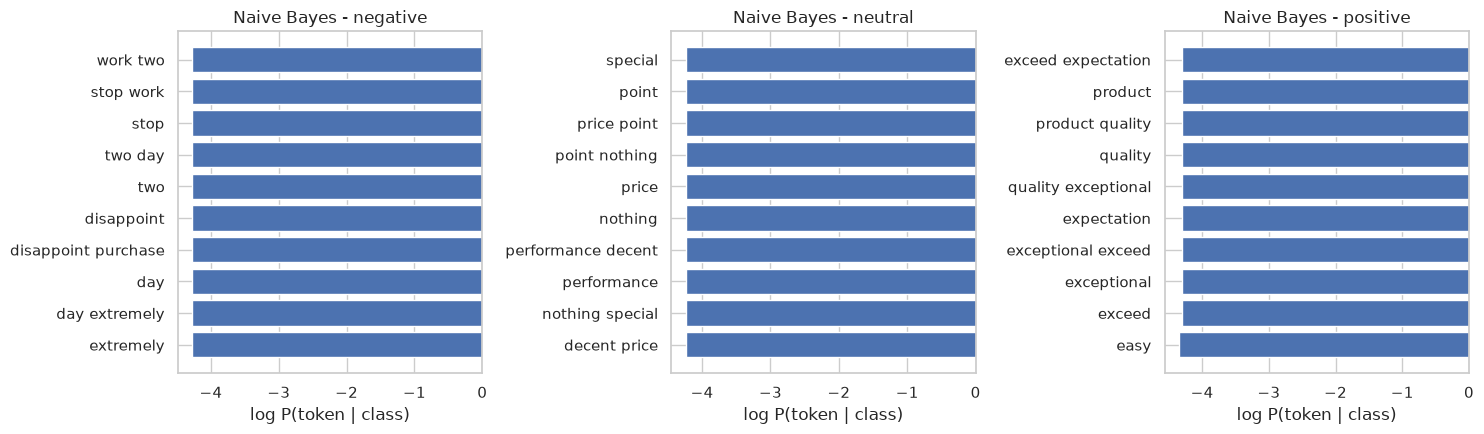

In [ ]:
fig, axes = plt.subplots(1, len(nb.classes_), figsize=(15, 4.5), sharey=False)
for ax, label, scores in zip(np.atleast_1d(axes), nb.classes_, nb.feature_log_prob_):
    top_idx = np.argsort(scores)[-10:]
    ax.barh(feature_names[top_idx], scores[top_idx])
    ax.set_title(f"Naive Bayes - {label}")
    ax.set_xlabel("log P(token | class)")
plt.tight_layout()
plt.show()

## 9. Cross-Validation

In [ ]:
# The starter file has only one neutral review, so a stratified split is impossible;
# KFold gives a slightly more stable estimate than a single train/test split.
cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=1)),
    ("model", MultinomialNB()),
])

cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
for scoring in ["accuracy", "f1_macro"]:
    scores = cross_val_score(cv_pipeline, X, y, cv=cv, scoring=scoring)
    print(f"Naive Bayes CV {scoring:>9}: {scores.round(3)}  "
          f"mean = {scores.mean():.3f} (+/- {scores.std():.3f})")

Naive Bayes CV  accuracy: [0.5   0.    0.333]  mean = 0.278 (+/- 0.208)
Naive Bayes CV  f1_macro: [0.333 0.    0.25 ]  mean = 0.194 (+/- 0.142)


## 10. `predict_sentiment()` + Interactive Test Helper

In [ ]:
# Final model trained on all available labelled reviews for live predictions
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=1)),
    ("model", MultinomialNB()),
])
final_model.fit(df["clean_text"], df["sentiment"])


def predict_sentiment(text):
    """Return the predicted sentiment, confidence and cleaned text for a review."""
    cleaned = clean_text(text)
    if not cleaned.strip():
        return {"sentiment": "unknown", "confidence": 0.0, "clean_text": cleaned,
                "probabilities": {}}

    proba = final_model.predict_proba([cleaned])[0]
    classes = final_model.classes_
    best = int(np.argmax(proba))
    return {
        "sentiment": classes[best],
        "confidence": round(float(proba[best]), 3),
        "clean_text": cleaned,
        "probabilities": {c: round(float(p), 3) for c, p in zip(classes, proba)},
    }

In [ ]:
samples = [
    "Absolutely love this product, it works perfectly!",
    "Worst purchase ever. It broke on day one.",
    "The item is okay, does the job but nothing special.",
    "Battery dies quickly, but the screen is nice.",
    "Customer support never replied to my emails.",
]

pd.DataFrame([{"review": s, **predict_sentiment(s)} for s in samples])

,review,sentiment,confidence,clean_text,probabilities
0,"Absolutely love this product, it works perfectly!",positive,0.599,absolutely love product work perfectly,"{'negative': 0.314, 'neutral': 0.086, 'positiv..."
1,Worst purchase ever. It broke on day one.,negative,0.481,worst purchase ever break day one,"{'negative': 0.481, 'neutral': 0.092, 'positiv..."
2,"The item is okay, does the job but nothing spe...",positive,0.433,item okay job nothing special,"{'negative': 0.412, 'neutral': 0.154, 'positiv..."
3,"Battery dies quickly, but the screen is nice.",positive,0.500,battery die quickly screen nice,"{'negative': 0.4, 'neutral': 0.1, 'positive': ..."
4,Customer support never replied to my emails.,positive,0.551,customer support never reply email,"{'negative': 0.357, 'neutral': 0.092, 'positiv..."


In [ ]:
def test_sentiment(text):
    """Small helper for testing one review at a time."""
    result = predict_sentiment(text)
    print(f"Review    : {text}")
    print(f"Sentiment : {result['sentiment']}  (confidence {result['confidence']:.1%})")
    print(f"Cleaned   : {result['clean_text']}")
    return result


test_sentiment("Great value and durable build. Would definitely purchase again.")

Review    : Great value and durable build. Would definitely purchase again.
Sentiment : positive  (confidence 66.6%)
Cleaned   : great value durable build would definitely purchase


{'sentiment': np.str_('positive'),
 'confidence': 0.666,
 'clean_text': 'great value durable build would definitely purchase',
 'probabilities': {np.str_('negative'): 0.254,
  np.str_('neutral'): 0.08,
  np.str_('positive'): 0.666}}

In [ ]:
def interactive_sentiment_helper():
    """Widget UI for live testing, with a graceful fallback when ipywidgets is absent."""
    try:
        import ipywidgets as widgets
        from IPython.display import display, clear_output
    except ImportError:
        print("ipywidgets is not installed - use test_sentiment('your review') instead.")
        return

    box = widgets.Textarea(
        placeholder="Type a customer review...",
        layout=widgets.Layout(width="100%", height="80px"),
    )
    button = widgets.Button(description="Predict sentiment", button_style="primary")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            if box.value.strip():
                print(predict_sentiment(box.value))
            else:
                print("Please type a review first.")

    button.on_click(on_click)
    display(widgets.VBox([box, button, output]))


interactive_sentiment_helper()

ipywidgets is not installed - use test_sentiment('your review') instead.


## 11. Summary

- Built a full NLP pipeline: clean/tokenize text (lowercase, HTML/URL/punctuation removal, stopword filtering with negations kept, lemmatization) -> TF-IDF (`max_features=5000`, unigrams + bigrams) -> classifiers.
- Compared **Multinomial Naive Bayes** and **Logistic Regression** with accuracy, macro/weighted F1, classification reports and confusion matrices.
- Inspected the most informative TF-IDF tokens per class and validated with 3-fold cross-validation.
- Exposed a reusable `predict_sentiment()` function, a `test_sentiment()` helper and an interactive widget for live review testing.
